In [1]:
import tensorflow as tf
import zipfile
import numpy as np
import random
import os
from tqdm import tqdm
from skimage.io import imread, imshow
from skimage.transform import resize
import matplotlib.pyplot as plt

import warnings

warnings.filterwarnings('ignore')
from PIL import Image

# # Load the extension and start TensorBoard

# %load_ext tensorboard
# %tensorboard --logdir logs

In [2]:
SEED = 42
np.random.seed = SEED

#UNZIP_PATH = '../input/data-science-bowl-2018/'
TRAIN_PATH = r'C:\Users\Kasia\Documents\GitHub\nails_segmentation\dataset\processed\train'
TEST_PATH = r'C:\Users\Kasia\Documents\GitHub\nails_segmentation\dataset\processed\test'
VAL_PATH = r'C:\Users\Kasia\Documents\GitHub\nails_segmentation\dataset\processed\val'

TRAIN_Y_PATH =r'C:\Users\Kasia\Documents\GitHub\nails_segmentation\dataset\processed\train_labels'
TEST_Y_PATH= r'C:\Users\Kasia\Documents\GitHub\nails_segmentation\dataset\processed\test_labels'
VAL_Y_PATH =r'C:\Users\Kasia\Documents\GitHub\nails_segmentation\dataset\processed\val_labels'


IMG_WIDTH_TEST = 800 #512
IMG_HEIGHT_TEST = 800 #384
IMG_CHANNELS_TEST = 3

IMG_WIDTH_TRAIN = 800 #512
IMG_HEIGHT_TRAIN = 800 #384
IMG_CHANNELS_TRAIN = 3

In [3]:
# get list of all subfolders
train_ids = next(os.walk(TRAIN_PATH))[1]
test_ids = next(os.walk(TEST_PATH))[1]
val_ids = next(os.walk(VAL_PATH))[1]

2it [00:00, 25.73it/s]
4it [00:00, 133.76it/s]
46it [00:00, 128.56it/s]


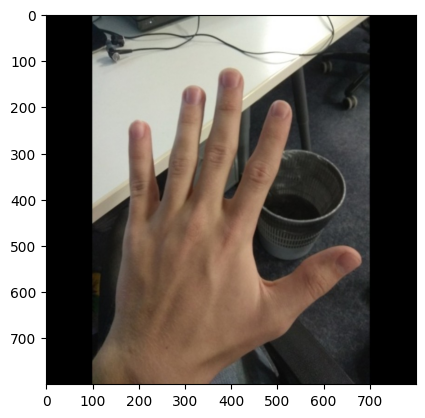

In [4]:
X_test = np.zeros((len(os.listdir(TEST_PATH)), IMG_WIDTH_TEST, IMG_HEIGHT_TEST, IMG_CHANNELS_TEST))

for i, element in tqdm(enumerate(os.listdir(TEST_PATH))):
    image = plt.imread(os.path.join(TEST_PATH, element))
    X_test[i] = image
    plt.imshow(image)



Val_train = np.zeros((len(os.listdir(VAL_PATH)), IMG_WIDTH_TRAIN, IMG_HEIGHT_TRAIN, IMG_CHANNELS_TRAIN))

for i, element in tqdm(enumerate(os.listdir(VAL_PATH))):
    image = plt.imread(os.path.join(VAL_PATH, element))
    Val_train[i] = image

    
X_train = np.zeros((len(os.listdir(TRAIN_PATH)), IMG_WIDTH_TRAIN, IMG_HEIGHT_TRAIN, IMG_CHANNELS_TRAIN))

for i, element in tqdm(enumerate(os.listdir(TRAIN_PATH))):
    image = plt.imread(os.path.join(TRAIN_PATH, element))
    X_train[i] = image

In [5]:
Y_train = np.zeros((len(os.listdir(TRAIN_Y_PATH)), IMG_WIDTH_TEST, IMG_HEIGHT_TEST))

for i, element in tqdm(enumerate(os.listdir(TRAIN_Y_PATH))):
    image = plt.imread(os.path.join(TRAIN_Y_PATH, element))
    Y_train[i] = np.where(np.mean(image, axis=2) > 254, 1, 0)


Y_valid = np.zeros((len(os.listdir(VAL_Y_PATH)), IMG_WIDTH_TEST, IMG_HEIGHT_TEST))

for i, element in tqdm(enumerate(os.listdir(VAL_Y_PATH))):
    image = plt.imread(os.path.join(VAL_Y_PATH, element))
    Y_valid[i] = np.where(np.mean(image, axis=2) > 254, 1, 0)

Y_test = np.zeros((len(os.listdir(TEST_Y_PATH)), IMG_WIDTH_TRAIN, IMG_HEIGHT_TRAIN))

for i, element in tqdm(enumerate(os.listdir(TEST_Y_PATH))):
    image = plt.imread(os.path.join(TEST_Y_PATH, element))
    Y_test[i] = np.where(np.mean(image, axis=2) > 254, 1, 0)
    # print(Y_test[i].shape, np.mean(Y_test[i], axis=2).shape, np.unique(np.where(np.mean(Y_test[i], axis=2) > 250, 1, 0)))
    # plt.figure()
    # plt.imshow(image)
    # plt.show()

    # plt.figure()
    # plt.imshow(Y_test[i], cmap='binary_r')
    # plt.show()

46it [00:00, 70.27it/s]
4it [00:00, 72.97it/s]
2it [00:00, 71.67it/s]


In [6]:
def resize(input_image, input_mask):
    input_image = tf.image.resize(input_image, (128, 128), method="nearest")
    if len(input_mask.shape) == 2:
        # Expand dimensions for single-channel mask
        input_mask = tf.expand_dims(input_mask, axis=-1)
    elif len(input_mask.shape) == 1:
        # Reshape 1D mask to 2D mask
        input_mask = tf.reshape(input_mask, (input_mask.shape[0], 1))
        # Expand dimensions for single-channel mask
        input_mask = tf.expand_dims(input_mask, axis=-1)
    #print(input_mask.shape)
    input_mask = tf.image.resize(input_mask, (128, 128), method="nearest")
    return input_image, input_mask 

In [7]:
def augment(input_image, input_mask):
    if tf.random.uniform(()) > 0.5:
        # Random flipping of the image and mask
        input_image = tf.image.flip_left_right(input_image)
        input_mask = tf.image.flip_left_right(input_mask)

    return input_image, input_mask

In [8]:
def normalize(input_image, input_mask):
    input_image = tf.cast(input_image, tf.float32) / 255.0
    #input_mask = tf.cast(input_mask, tf.float32) / 255.0
    input_mask -= 1
    input_mask= np.where(input_mask == -1, 1, input_mask)
  
    return input_image, input_mask

In [9]:
# Define the target shape for the images and masks
target_shape = (128, 128)
# Define the dataset structure
# dataset_structure = {
#     'image': tf.TensorSpec(shape=(target_shape[0], target_shape[1], 3), dtype=tf.float32),
#     'segmentation_mask': tf.TensorSpec(shape=(target_shape[0], target_shape[1], 1), dtype=tf.uint8)
# }

# Define the dataset structure
dataset_structure = {
    'image': tf.TensorSpec(shape=(target_shape[0], target_shape[1], 3), dtype=tf.float32),
    'segmentation_mask': tf.TensorSpec(shape=(target_shape[0], target_shape[1], 1), dtype=tf.uint8)
}

In [10]:
Y_train[45]

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [11]:
#training dataset
data_tr = []
for i in range(len(Y_train)):
    input_image = X_train[i]
    input_mask = Y_train[i]
    input_image, input_mask = resize(input_image, input_mask)
    #print(len(input_image))
    input_image, input_mask = augment(input_image, input_mask)
    input_image, input_mask = normalize(input_image, input_mask)
    # Add a batch dimension to the input image and mask
    input_image = tf.expand_dims(input_image, axis=0)
    input_mask = tf.expand_dims(input_mask, axis=0)
    data_tr.append({'image': input_image, 'segmentation_mask': input_mask})

print(i, input_mask)

45 tf.Tensor(
[[[[1.]
   [1.]
   [1.]
   ...
   [1.]
   [1.]
   [1.]]

  [[1.]
   [1.]
   [1.]
   ...
   [1.]
   [1.]
   [1.]]

  [[1.]
   [1.]
   [1.]
   ...
   [1.]
   [1.]
   [1.]]

  ...

  [[1.]
   [1.]
   [1.]
   ...
   [1.]
   [1.]
   [1.]]

  [[1.]
   [1.]
   [1.]
   ...
   [1.]
   [1.]
   [1.]]

  [[1.]
   [1.]
   [1.]
   ...
   [1.]
   [1.]
   [1.]]]], shape=(1, 128, 128, 1), dtype=float64)


In [12]:
input_image = X_train[i]
input_mask = Y_train[i]
#print("beginnig", np.unique(input_mask))
input_image, input_mask = resize(input_image, input_mask)
    #print(len(input_image))
#print("after resize",np.unique(input_mask, return_counts=True))
input_image, input_mask = augment(input_image, input_mask)
#print("after augment",np.unique(input_mask, return_counts=True))
input_image, input_mask = normalize(input_image, input_mask)
#print("after normalize",np.unique(input_mask, return_counts=True))
    # Add a batch dimension to the input image and mask
input_image = tf.expand_dims(input_image, axis=0)
input_mask = tf.expand_dims(input_mask, axis=0)
#print("after expanding", np.unique(input_mask, return_counts=True))

In [13]:
data_test=[]
for i in range(len(Y_test)):
    input_image = X_test[i]
    input_mask = Y_test[i]
    input_image, input_mask = resize(input_image, input_mask)
    input_image, input_mask = normalize(input_image, input_mask)
    # Add a batch dimension to the input image and mask
    input_image = tf.expand_dims(input_image, axis=0)
    input_mask = tf.expand_dims(input_mask, axis=0)
    data_test.append({'image': input_image, 'segmentation_mask': input_mask})


In [14]:
#print(i, input_mask)
#print(i, input_mask) [16305,    79]
#array([  0, 255], dtype=uint8), array([  120, 16264],

In [15]:
data_val=[]
for i in range(len(Y_valid)):
    input_image = Val_train[i]
    input_mask = Y_valid[i]
    input_image, input_mask = resize(input_image, input_mask)
    input_image, input_mask = normalize(input_image, input_mask)
    # Add a batch dimension to the input image and mask
    input_image = tf.expand_dims(input_image, axis=0)
    input_mask = tf.expand_dims(input_mask, axis=0)
    data_val.append({'image': input_image, 'segmentation_mask': input_mask})

In [16]:
#print(i, input_mask)


In [17]:
# def generator_1():
#     for sample in data_tr:
#         yield sample

def generator_1():
    for sample in data_tr:
        image = tf.squeeze(sample['image'])
        mask = tf.squeeze(sample['segmentation_mask'])
        mask = tf.where(mask == 255, 1, mask)
        mask = tf.expand_dims(tf.squeeze(sample['segmentation_mask']), axis=-1)
        yield {'image': image, 'segmentation_mask': mask}
# def generator_2():
#     for sample in data_test:
#         yield sample
def generator_2():
    for sample in data_test:
        image = tf.squeeze(sample['image'])
        mask = tf.squeeze(sample['segmentation_mask'])
        mask = tf.where(mask == 255, tf.ones_like(mask), mask)
        mask = tf.expand_dims(tf.squeeze(sample['segmentation_mask']), axis=-1)

        yield {'image': image, 'segmentation_mask': mask}

def generator_3():
    for sample in data_val:
        image = tf.squeeze(sample['image'])
        mask = tf.squeeze(sample['segmentation_mask'])
        mask = tf.where(mask == 255, 1, mask)
        mask = tf.expand_dims(tf.squeeze(sample['segmentation_mask']), axis=-1)

        yield {'image': image, 'segmentation_mask': mask}

# def generator_3():
#     for sample in data_val:
#         yield sample


train_dataset = tf.data.Dataset.from_generator(generator_1, output_signature=dataset_structure)
test_dataset = tf.data.Dataset.from_generator(generator_2, output_signature=dataset_structure)
val_dataset = tf.data.Dataset.from_generator(generator_3, output_signature=dataset_structure)



something to visualize? 


In [18]:
BATCH_SIZE = 2  # was 64
BUFFER_SIZE = 100  #was 1000

In [19]:
train_batches = train_dataset.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE).repeat()
train_batches = train_batches.prefetch(buffer_size=tf.data.experimental.AUTOTUNE)
validation_batches = val_dataset.batch(BATCH_SIZE)
test_batches = test_dataset.batch(BATCH_SIZE)

In [20]:
def display(display_list):
  plt.figure(figsize=(15, 15))

  title = ["Input Image", "True Mask", "Predicted Mask"]

  for i in range(len(display_list)):
    plt.subplot(1, len(display_list), i+1)
    plt.title(title[i])
    plt.imshow(tf.keras.utils.array_to_img(display_list[i]))
    plt.axis("off")
  plt.show()

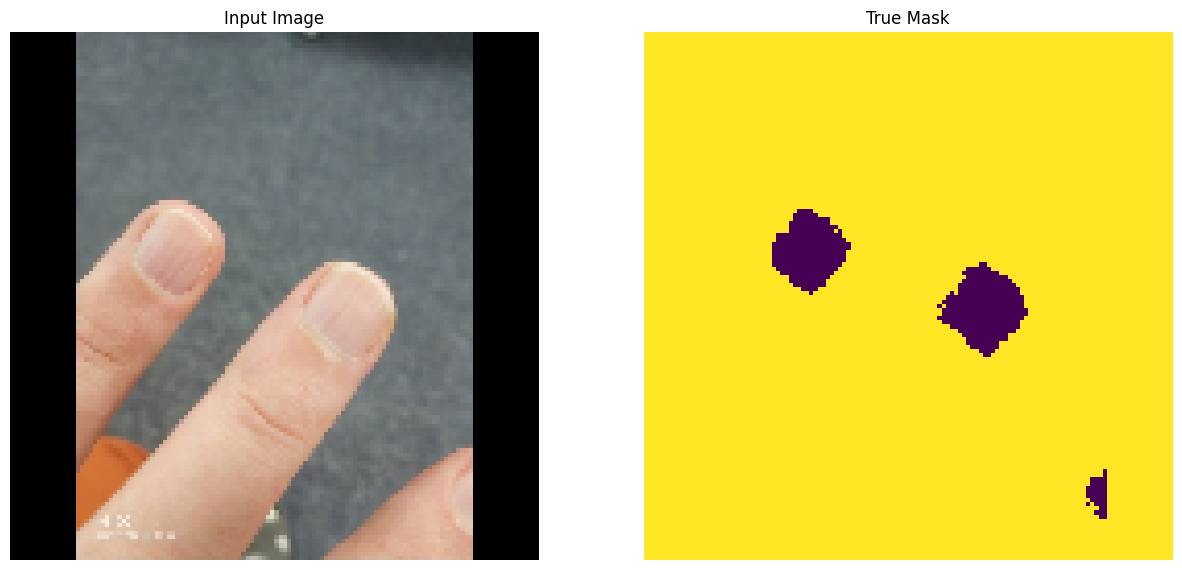

In [21]:
sample_batch = next(iter(test_batches))
# random_index = np.random.choice(sample_batch[0].shape[0])
# sample_image, sample_mask = sample_batch[0][random_index], sample_batch[1][random_index]
random_index = np.random.choice(sample_batch['image'].shape[0])
sample_image = sample_batch['image'][random_index]
sample_mask = sample_batch['segmentation_mask'][random_index]
#print(random_index)
display([sample_image, sample_mask])

In [22]:
import numpy as np
np.unique(sample_mask)
np.unique(sample_mask, return_counts=True)
# 0 -> target
# 1-> background
# 2 -> contour

# now is 
# 0 -> target
# 255 -> background
#print(sample_mask)

(array([0, 1], dtype=uint8), array([  593, 15791], dtype=int64))

probably change all the 255 to 1?

Building the model

In [23]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

In [24]:
def double_conv_block(x, n_filters):

    # Conv2D then ReLU activation
    x = layers.Conv2D(n_filters, 3, padding = "same", activation = "relu", kernel_initializer = "he_normal")(x)
    # Conv2D then ReLU activation
    x = layers.Conv2D(n_filters, 3, padding = "same", activation = "relu", kernel_initializer = "he_normal")(x)

    return x

def downsample_block(x, n_filters):
    f = double_conv_block(x, n_filters)
    p = layers.MaxPool2D(2)(f)
    p = layers.Dropout(0.3)(p)

    return f, p
    
def upsample_block(x, conv_features, n_filters):
    # upsample
    x = layers.Conv2DTranspose(n_filters, 3, 2, padding="same")(x)
    # concatenate 
    x = layers.concatenate([x, conv_features])
    # dropout
    x = layers.Dropout(0.3)(x)
    # Conv2D twice with ReLU activation
    x = double_conv_block(x, n_filters)

    return x

In [25]:
def build_unet_model():

    # inputs
    inputs = layers.Input(shape=(128,128,3), name="inputs")

    # encoder: contracting path - downsample
    # 1 - downsample
    f1, p1 = downsample_block(inputs, 64)
    # 2 - downsample
    f2, p2 = downsample_block(p1, 128)
    # 3 - downsample
    f3, p3 = downsample_block(p2, 256)
    # 4 - downsample
    f4, p4 = downsample_block(p3, 512)

    # 5 - bottleneck
    bottleneck = double_conv_block(p4, 1024)

    # decoder: expanding path - upsample
    # 6 - upsample
    u6 = upsample_block(bottleneck, f4, 512)
    # 7 - upsample
    u7 = upsample_block(u6, f3, 256)
    # 8 - upsample
    u8 = upsample_block(u7, f2, 128)
    # 9 - upsample
    u9 = upsample_block(u8, f1, 64)

    # outputs
    #outputs = layers.Conv2D(3, 1, padding="same", activation = "softmax")(u9)
    outputs = layers.Conv2D(3, 1, padding="same", activation = "softmax", name="outputs")(u9)

    # unet model with Keras Functional API
    unet_model = tf.keras.Model(inputs, outputs, name="U-Net")

    return unet_model

In [26]:
unet_model = build_unet_model()
#unet_model.summary()
#tf.keras.utils.plot_model(unet_model, show_shapes=True)
tf.keras.backend.clear_session()


Compile and train 

In [27]:
unet_model.compile(optimizer=tf.keras.optimizers.Adam(),
                   loss="sparse_categorical_crossentropy",
                   metrics="accuracy")

In [28]:
train_dataset2 = train_dataset.map(lambda x: {'image': x['image'], 'segmentation_mask': x['segmentation_mask']})

data_dict = {
    'inputs': [],
    'segmentation_mask': []
}

for item in train_dataset2:
    data_dict['inputs'].append(item['image'])
    data_dict['segmentation_mask'].append(item['segmentation_mask'])

data_dict['inputs'] = np.array(data_dict['inputs'])
data_dict['segmentation_mask'] = np.array(data_dict['segmentation_mask'])

# Create a data dictionary with the necessary inputs
input_dict = {
    'inputs': data_dict['inputs'],  # Pass the input image data
}

# Create a data dictionary with the necessary outputs
output_dict = {
    'outputs': data_dict['segmentation_mask']   # Pass the output mask data
}

In [29]:
validation_dict = {
    'inputs': [],
    'segmentation_mask': []
}

for item in val_dataset:
    validation_dict['inputs'].append(item['image'])
    validation_dict['segmentation_mask'].append(item['segmentation_mask'])

validation_dict['inputs'] = np.array(validation_dict['inputs'])
validation_dict['segmentation_mask'] = np.array(validation_dict['segmentation_mask'])

# Create a data dictionary for validation inputs
validation_input_dict = {
    'inputs': validation_dict['inputs']
}

# Create a data dictionary for validation outputs
validation_output_dict = {
    'outputs': validation_dict['segmentation_mask']
}


In [30]:
validation_input_dict.keys()
validation_output_dict.keys()

dict_keys(['outputs'])

In [31]:
print("Validation inputs shape:", validation_input_dict['inputs'].shape)
print("Validation outputs shape:", validation_output_dict['outputs'].shape)


Validation inputs shape: (4, 128, 128, 3)
Validation outputs shape: (4, 128, 128, 1)


In [40]:
NUM_EPOCHS = 20

#TRAIN_LENGTH = info.splits["train"].num_examples
TRAIN_LENGTH = len(X_train)
STEPS_PER_EPOCH = TRAIN_LENGTH // BATCH_SIZE

VAL_SUBSPLITS = 2
#TEST_LENTH = info.splits["test"].num_examples
TEST_LENTH = len(Val_train)
VALIDATION_STEPS = TEST_LENTH // BATCH_SIZE // VAL_SUBSPLITS

# model_history = unet_model.fit(train_batches,
#                                epochs=NUM_EPOCHS,
#                                steps_per_epoch=STEPS_PER_EPOCH,
#                                validation_steps=VALIDATION_STEPS,
#                                validation_data=validation_batches)

# Now you can use the data dictionaries in the fit method
model_history = unet_model.fit(x=input_dict, y=output_dict,
                              epochs=NUM_EPOCHS,
                              steps_per_epoch=STEPS_PER_EPOCH,
                              validation_steps=VALIDATION_STEPS,
                              #validation_data=validation_batches)
                              validation_data=(validation_input_dict, validation_output_dict))




Epoch 1/20


23/23 [==============================] - 22s 968ms/step - loss: 0.0926 - accuracy: 0.9686 - val_loss: 0.0815 - val_accuracy: 0.9760
Epoch 2/20
23/23 [==============================] - 22s 965ms/step - loss: 0.0908 - accuracy: 0.9696 - val_loss: 0.0794 - val_accuracy: 0.9757
Epoch 3/20
23/23 [==============================] - 22s 968ms/step - loss: 0.0828 - accuracy: 0.9705 - val_loss: 0.0780 - val_accuracy: 0.9696
Epoch 4/20
23/23 [==============================] - 23s 986ms/step - loss: 0.0766 - accuracy: 0.9731 - val_loss: 0.0870 - val_accuracy: 0.9766
Epoch 5/20
23/23 [==============================] - 22s 976ms/step - loss: 0.0939 - accuracy: 0.9685 - val_loss: 0.0742 - val_accuracy: 0.9756
Epoch 6/20
23/23 [==============================] - 22s 974ms/step - loss: 0.0854 - accuracy: 0.9691 - val_loss: 0.0792 - val_accuracy: 0.9759
Epoch 7/20
23/23 [==============================] - 22s 969ms/step - loss: 0.0713 - accuracy: 0.9719 - val_loss: 0.0764 - val_accuracy: 0.9752
Epoch 8/20

learning curves from history

In [41]:
def display_learning_curves(history):
    acc = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]

    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs_range = range(NUM_EPOCHS)

    fig = plt.figure(figsize=(12,6))

    plt.subplot(1,2,1)
    plt.plot(epochs_range, acc, label="train accuracy")
    plt.plot(epochs_range, val_acc, label="validataion accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend(loc="lower right")

    plt.subplot(1,2,2)
    plt.plot(epochs_range, loss, label="train loss")
    plt.plot(epochs_range, val_loss, label="validataion loss")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(loc="upper right")

    fig.tight_layout()
    plt.show()

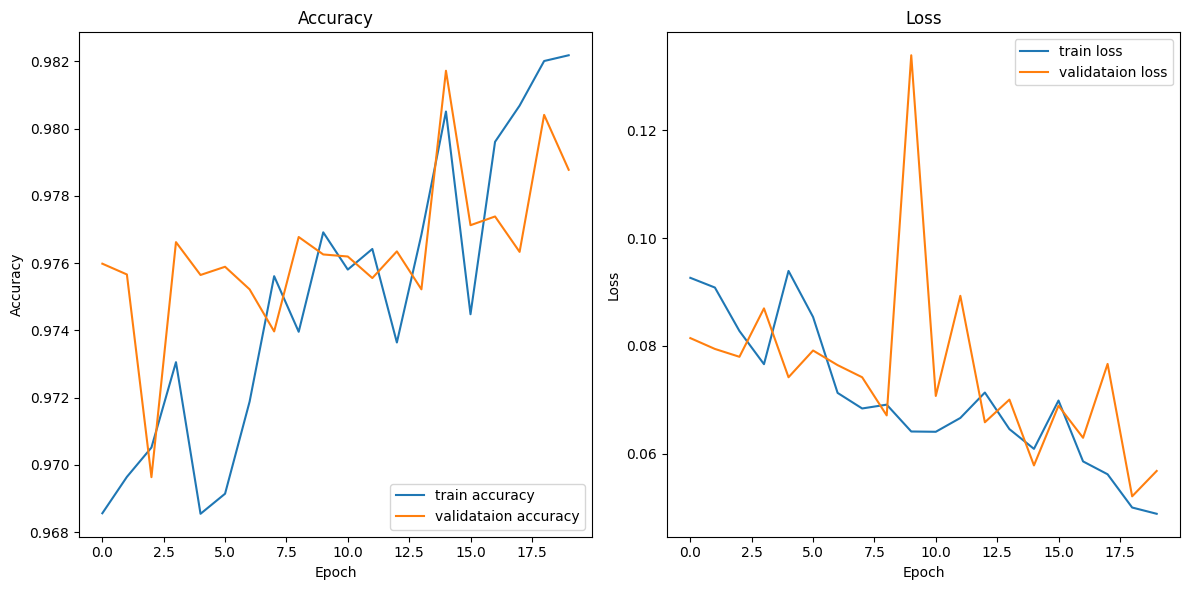

In [42]:
# Display learning curves 
display_learning_curves(unet_model.history)

In [ ]:
unet_model.save("final_model_faint.h5")

Prediction

In [43]:
def create_mask(pred_mask):
  pred_mask = tf.argmax(pred_mask, axis=-1)
  pred_mask = pred_mask[..., tf.newaxis]
  return pred_mask[0]

In [44]:
from PIL import Image
# Path to the JPEG image
image_path=r"C:\Users\Kasia\Desktop\paznokcie.jpg"
# Load the image using PIL
image_pil = Image.open(image_path)

# Convert the PIL image to a NumPy array
image_np = tf.keras.preprocessing.image.img_to_array(image_pil)

# Create an EagerTensor from the NumPy array
image_tensor = tf.convert_to_tensor(image_np)

In [45]:
# Add an extra dimension to represent the batch size
image_tensor_batch = tf.expand_dims(image_tensor, axis=0)

# Resize the image tensor to match the expected input shape of the U-Net model
image_tensor_resized = tf.image.resize(image_tensor_batch, [128, 128])

# Normalize the image tensor to be in the range [0, 1]
image_tensor_normalized = image_tensor_resized / 255.0

# Make predictions with the U-Net model
pred_mask = unet_model.predict(image_tensor_normalized)
#plt.imshow(tf.keras.utils.array_to_img(image_tensor_normalized))
#plt.imshow(tf.keras.utils.array_to_img(pred_mask))

1/1 [==============================] - 0s 141ms/step


In [46]:
# Add an extra dimension to represent the batch size
image_tensor_batch = tf.expand_dims(image_tensor, axis=0)

# Resize the image tensor to match the expected input shape of the U-Net model
image_tensor_resized = tf.image.resize(image_tensor_batch, [128, 128])

# Normalize the image tensor to be in the range [0, 1]
image_tensor_normalized = image_tensor_resized / 255.0
print(image_tensor_normalized.shape)

# Make predictions with the U-Net model
pred_mask = unet_model.predict(image_tensor_normalized)
#plt.imshow(tf.keras.utils.array_to_img(image_tensor_normalized))
#plt.imshow(tf.keras.utils.array_to_img(pred_mask))

(1, 128, 128, 3)
1/1 [==============================] - 0s 173ms/step


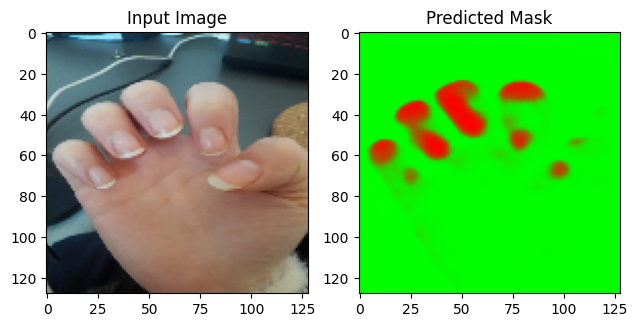

In [47]:
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2)

# Remove the batch dimension from the image
image = image_tensor_normalized[0]

# Convert the image tensor to a PIL image
image_pil = tf.keras.utils.array_to_img(image)

# Display the image in the first subplot
axes[0].imshow(image_pil)
axes[0].set_title('Input Image')

# Select the first mask from the batch
pred_mask_single = pred_mask[0]

# Convert the mask tensor to a PIL image
pred_mask_pil = tf.keras.utils.array_to_img(pred_mask_single)

# Display the predicted mask in the second subplot
axes[1].imshow(pred_mask_pil)
axes[1].set_title('Predicted Mask')

# Adjust the spacing between subplots
plt.tight_layout()

# Show the figure
plt.show()

